# 02 · Text preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/02_text_preprocessing.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 2 of 12*

In notebook 01 we saw that raw text is messy: `The` and `the` are different "words", punctuation sticks
to tokens, and function words dominate every count. **Preprocessing** turns raw text into a clean list
of meaningful tokens. Every choice you make here changes the vocabulary — and therefore every model
built on top of it.

### Learning objectives
By the end of this notebook you will be able to:
1. Tokenize text into sentences and words, and compare naive and linguistic tokenizers.
2. Decide when to lowercase and when to remove stopwords — and when *not* to.
3. Explain the difference between **stemming** and **lemmatization**, and apply both with NLTK.
4. Clean text with **regular expressions** (URLs, e-mail addresses, numbers, punctuation).
5. Build a reusable `preprocess()` function and measure its effect on a real corpus.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from collections import Counter
import re
from nltk.tokenize import word_tokenize, sent_tokenize

df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
print(f"{len(train):,} training documents")

2,239 training documents


## 1 · Tokenization
**Tokenization** splits text into units — usually words (word tokenization) or sentences (sentence
tokenization). It sounds trivial; it is not. Look at this sentence:

In [3]:
tricky = ("Dr. Smith's team didn't launch the U.S. rocket on 12/04/1993 -- it cost $3.5M! "
          "E-mail questions to someone@example.com or see http://www.example.org/space.")

print("1) str.split():")
print(tricky.split(), "\n")
print("2) regex \\w+ :")
print(re.findall(r"\w+", tricky), "\n")
print("3) NLTK word_tokenize:")
print(word_tokenize(tricky))

1) str.split():
['Dr.', "Smith's", 'team', "didn't", 'launch', 'the', 'U.S.', 'rocket', 'on', '12/04/1993', '--', 'it', 'cost', '$3.5M!', 'E-mail', 'questions', 'to', 'someone@example.com', 'or', 'see', 'http://www.example.org/space.'] 

2) regex \w+ :
['Dr', 'Smith', 's', 'team', 'didn', 't', 'launch', 'the', 'U', 'S', 'rocket', 'on', '12', '04', '1993', 'it', 'cost', '3', '5M', 'E', 'mail', 'questions', 'to', 'someone', 'example', 'com', 'or', 'see', 'http', 'www', 'example', 'org', 'space'] 

3) NLTK word_tokenize:
['Dr.', 'Smith', "'s", 'team', 'did', "n't", 'launch', 'the', 'U.S.', 'rocket', 'on', '12/04/1993', '--', 'it', 'cost', '$', '3.5M', '!', 'E-mail', 'questions', 'to', 'someone', '@', 'example.com', 'or', 'see', 'http', ':', '//www.example.org/space', '.']


| Tokenizer | Strength | Weakness |
|---|---|---|
| `str.split()` | fast, simple | punctuation stays glued: `rocket,` ≠ `rocket` |
| regex `\w+` | removes punctuation | breaks `U.S.`, `didn't`, `e-mail`, numbers into pieces |
| NLTK `word_tokenize` | knows English rules: splits `didn't` → `did` + `n't`, keeps `Dr.`, `$`, `3.5M` | slower; still has to decide about URLs and e-mails |

**Sentence tokenization** has its own trap: a full stop does not always end a sentence (`Dr.`, `U.S.`).
NLTK's Punkt model learned the common English abbreviations:

In [4]:
text = "Dr. Smith works at NASA. He flew to the U.S. space station in 1998. Amazing, isn't it?"
print("naive split on '. ':", text.split(". "))
print()
for i, s in enumerate(sent_tokenize(text), 1):
    print(i, s)

naive split on '. ': ['Dr', 'Smith works at NASA', 'He flew to the U.S', 'space station in 1998', "Amazing, isn't it?"]

1 Dr. Smith works at NASA.
2 He flew to the U.S. space station in 1998.
3 Amazing, isn't it?


Let's tokenize a real newsgroup post.

In [5]:
doc = train[(train["category"] == "sci.space") & train["text"].str.len().between(400, 900)].iloc[0]
print(doc.text.strip())

Sounds liek what the FED has to do is sign a 50 or more year lease to use
certain parts of a space station that is built and designed and such by a
commerical company or consortium of companies (such as like Alyeska) for a
small amount of rent in return for certain incentives and such.. Such as tax
and other right off and also a monopoly on certain products.. The commerical
builders would have certain perks given to them to make there end easier (taxes
, contracts, regulatory concesions and such..)

Is it workable, just might work..

After all, if China can lease out Hong Kong and the people of Hong Kong can
make money, this could work..


In [6]:
sents = sent_tokenize(doc.text)
words = word_tokenize(doc.text)
print(f"{len(sents)} sentences, {len(words)} word tokens")
print(words[:40])

3 sentences, 132 word tokens
['Sounds', 'liek', 'what', 'the', 'FED', 'has', 'to', 'do', 'is', 'sign', 'a', '50', 'or', 'more', 'year', 'lease', 'to', 'use', 'certain', 'parts', 'of', 'a', 'space', 'station', 'that', 'is', 'built', 'and', 'designed', 'and', 'such', 'by', 'a', 'commerical', 'company', 'or', 'consortium', 'of', 'companies', '(']


## 2 · Lowercasing
Lowercasing merges `The`, `THE` and `the` into one type. It almost always helps for topic-style tasks,
because it shrinks the vocabulary and pools the counts. But it can destroy information:
`US` (the country) vs `us`, `Apple` (company) vs `apple`, or shouting in spam (`FREE!!!`).

In [7]:
tokens = [t for text in train["text"] for t in word_tokenize(text)]
print(f"tokens: {len(tokens):,}")
print(f"types, original case: {len(set(tokens)):,}")
print(f"types, lowercased:    {len({t.lower() for t in tokens}):,}")

tokens: 509,679
types, original case: 38,959
types, lowercased:    32,627


In [8]:
# How often are the case-ambiguous examples used in each form?
cnt = Counter(tokens)
pd.DataFrame({w: [cnt[w], cnt[w.lower()], cnt[w.upper()]] for w in ["Us", "Apple", "Mars", "Bush"]},
             index=["Capitalised", "lower", "UPPER"])

,Us,Apple,Mars,Bush
Capitalised,4,14,83,48
lower,259,1,1,2
UPPER,155,0,17,2


## 3 · Stopwords
**Stopwords** are very frequent function words (*the, of, and, is, to…*) that carry grammar but little
topic. NLTK ships a list for English:

In [9]:
from nltk.corpus import stopwords
STOP = set(stopwords.words("english"))
print(len(STOP), "English stopwords. A sample:")
print(sorted(STOP)[:60])

198 English stopwords. A sample:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd"]


In [10]:
lower_tokens = [t.lower() for t in tokens]
alpha = [t for t in lower_tokens if t.isalpha()]
share = sum(t in STOP for t in alpha) / len(alpha)
print(f"Stopwords make up {share:.1%} of all alphabetic tokens in the training set.")

Stopwords make up 45.9% of all alphabetic tokens in the training set.


In [11]:
before = Counter(alpha).most_common(12)
after = Counter(t for t in alpha if t not in STOP).most_common(12)
pd.DataFrame({"top words (with stopwords)": [f"{w} ({c})" for w, c in before],
              "top words (stopwords removed)": [f"{w} ({c})" for w, c in after]})

,top words (with stopwords),top words (stopwords removed)
0,the (21021),would (1374)
1,to (10667),one (994)
2,of (9209),space (887)
3,and (8710),think (781)
4,a (8657),like (748)
5,in (6220),people (748)
6,is (5780),also (742)
7,i (5769),know (705)
8,that (5610),get (693)
9,it (4524),q (609)


After removing stopwords, the most frequent words start to look like **topics** — *space, people,
think, time…* — although modal verbs such as *would* and *could*, and leftovers like `q`, remain.

⚠️ **Be careful:** the NLTK list contains negations such as `not`, `no`, `nor` and `don't`. For
sentiment analysis, *"not good"* → *"good"* flips the meaning! Always check the list against your task.

In [12]:
print("negation-like words in the NLTK list:",
      sorted(w for w in STOP if w in {"not", "no", "nor"} or w.endswith("n't")))

negation-like words in the NLTK list: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't", 'no', 'nor', 'not', "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't"]


## 4 · Stemming vs lemmatization
Words come in many forms: *launch, launches, launched, launching*. For most counting-based methods we
want them to be **one** feature. There are two ways to get there.

**Stemming** chops suffixes with hand-written rules. It is fast and crude; the result (the *stem*) is
often not a real word. NLTK has three classic stemmers:
- **Porter** (1980) — the classic, moderate.
- **Snowball** ("Porter2") — an improved Porter, the usual default.
- **Lancaster** — the most aggressive.

In [13]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer
porter, snowball, lancaster = PorterStemmer(), SnowballStemmer("english"), LancasterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["launch", "launches", "launched", "launching", "studies", "studying", "better",
         "mice", "running", "ran", "generously", "university", "universe", "organization", "organ",
         "was", "graphics"]
pd.DataFrame({
    "Porter": [porter.stem(w) for w in words],
    "Snowball": [snowball.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words],
    "Lemma (noun)": [lemmatizer.lemmatize(w) for w in words],
    "Lemma (verb)": [lemmatizer.lemmatize(w, pos="v") for w in words],
}, index=words)

,Porter,Snowball,Lancaster,Lemma (noun),Lemma (verb)
launch,launch,launch,launch,launch,launch
launches,launch,launch,launch,launch,launch
launched,launch,launch,launch,launched,launch
launching,launch,launch,launch,launching,launch
studies,studi,studi,study,study,study
studying,studi,studi,study,studying,study
better,better,better,bet,better,better
mice,mice,mice,mic,mouse,mice
running,run,run,run,running,run
ran,ran,ran,ran,ran,run


What to notice in the table:

- **Over-stemming** — different words collapse to the same stem: *university* and *universe* both become
  `univers`; *organization* and *organ* both become `organ` with Porter.
- **Under-stemming** — related words stay apart: *ran* is not linked to *run*.
- Stems are not words: `studi`, `gener`.

**Lemmatization** maps each word to its dictionary form (the *lemma*) using a vocabulary — here
WordNet. *mice → mouse*, *studies → study*, *ran → run* (as a verb). It needs to know the **part of
speech**: `running` is unchanged as a noun but becomes `run` as a verb. A good, simple heuristic without
a part-of-speech tagger: lemmatize as a noun, then as a verb.

In [14]:
def lemma(word):
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos="n"), pos="v")

print({w: lemma(w) for w in ["mice", "running", "ran", "studies", "launched", "graphics", "was", "bit"]})

{'mice': 'mouse', 'running': 'run', 'ran': 'run', 'studies': 'study', 'launched': 'launch', 'graphics': 'graphic', 'was': 'wa', 'bit': 'bite'}


The heuristic is not perfect: `was` → `wa` (the noun pass treats it as a plural of *wa*) and `bit`
→ `bite` (read as the past tense of *bite*). Removing stopwords *before* lemmatizing avoids the first
problem; a part-of-speech tagger would avoid both. Every normaliser makes some mistakes — the goal is
fewer mistakes than it fixes.

| | Stemming | Lemmatization |
|---|---|---|
| Method | suffix-stripping rules | dictionary + morphology |
| Output | stem, may not be a word (`studi`) | a real word (`study`) |
| Speed | very fast | slower |
| Needs part of speech | no | yes, for best results |
| Typical use | search engines, large-scale retrieval | when features must stay readable |

## 5 · Regular expressions for cleaning
**Regular expressions** (regex) describe text patterns. In preprocessing we use them to remove or
replace things that are not useful words. A few building blocks:

| Pattern | Matches |
|---|---|
| `\d+` | one or more digits |
| `\s+` | whitespace (spaces, tabs, line breaks) |
| `[^A-Za-z\s]` | any character that is *not* a letter or whitespace |
| `https?://\S+` | a URL starting with http:// or https:// |
| `\S+@\S+\.\S+` | something that looks like an e-mail address |

In [15]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
NUMBER_RE = re.compile(r"\d+(?:[.,]\d+)*")
NON_LETTER_RE = re.compile(r"[^A-Za-z\s]")
SPACES_RE = re.compile(r"\s+")

for name, rx in [("URLs", URL_RE), ("e-mails", EMAIL_RE), ("numbers", NUMBER_RE)]:
    n_docs = train["text"].str.contains(rx).sum()
    print(f"{name:8s}: found in {n_docs:4d} of {len(train)} training documents")

URLs    : found in    0 of 2239 training documents
e-mails : found in  296 of 2239 training documents
numbers : found in 1227 of 2239 training documents


In [16]:
def clean_text(text):
    """Remove URLs, e-mail addresses, numbers and every non-letter character."""
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = NUMBER_RE.sub(" ", text)
    text = NON_LETTER_RE.sub(" ", text)
    return SPACES_RE.sub(" ", text).strip()

print("BEFORE:", tricky)
print("AFTER: ", clean_text(tricky))

BEFORE: Dr. Smith's team didn't launch the U.S. rocket on 12/04/1993 -- it cost $3.5M! E-mail questions to someone@example.com or see http://www.example.org/space.
AFTER:  Dr Smith s team didn t launch the U S rocket on it cost M E mail questions to or see


No URLs at all — these posts are from 1993, when the web barely existed! E-mail addresses and
numbers, however, are everywhere. Here is a real post that contains an e-mail address. To protect people's privacy we only
print the cleaned version and the *number* of matches.

In [17]:
has_url = train[train["text"].str.contains(EMAIL_RE) & train["text"].str.len().between(200, 1200)].iloc[0]
print("category:", has_url.category, "| URLs:", len(URL_RE.findall(has_url.text)),
      "| e-mails:", len(EMAIL_RE.findall(has_url.text)), "| numbers:", len(NUMBER_RE.findall(has_url.text)))
print()
print(clean_text(has_url.text)[:600])

category: comp.graphics | URLs: 0 | e-mails: 1 | numbers: 11

G day all Can anybody point me at a utility which will read convert crop whatnot display HDF image files I ve had a look at the HDF stuff under NCSA and it must take an award for odd directory structure strange storage approaches and minimalist documentation Part of the problem is that I want to look at large MB HDF files and crop out a section Ideally I would like a hdftoppm type of utility from which I can then use the PBMplus stuff quite merrily I can convert the cropped part into another format for viewing animation Otherwise can someone please explain how to set up the NCSA Visualisation 


## 6 · Putting it together: a reusable `preprocess()` function
We chain the steps in a sensible order:

1. **clean** with regex (URLs, e-mails, numbers, punctuation),
2. **lowercase**,
3. **tokenize** with NLTK,
4. **remove stopwords** (optionally keeping some, such as negations) and very short tokens,
5. **normalise** each token by lemmatization or stemming.

Every step is a parameter, so we can switch it off and measure its effect.

In [18]:
def preprocess(text, lowercase=True, remove_stopwords=True, normalize="lemma", min_len=2, keep=frozenset()):
    """Clean -> lowercase -> tokenize -> drop stopwords/short tokens -> lemma or stem."""
    text = clean_text(text)
    if lowercase:
        text = text.lower()
    tokens = word_tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t.lower() not in STOP or t.lower() in keep]
    tokens = [t for t in tokens if len(t) >= min_len]
    if normalize == "lemma":
        tokens = [lemma(t) for t in tokens]
    elif normalize == "stem":
        tokens = [porter.stem(t) for t in tokens]
    return tokens

print(preprocess(tricky))
print(preprocess(tricky, normalize="stem"))
print(preprocess("This is not good, I don't like it.", keep={"not"}))

['dr', 'smith', 'team', 'launch', 'rocket', 'cost', 'mail', 'question', 'see']
['dr', 'smith', 'team', 'launch', 'rocket', 'cost', 'mail', 'question', 'see']
['not', 'good', 'like']


The same function lives in the course helper module as `nlp_course.preprocess`, so later notebooks
can simply import it. Let's confirm both give identical results on real documents:

In [19]:
sample = train["text"].iloc[:200]
assert all(preprocess(t) == nlp_course.preprocess(t) for t in sample)
assert all(preprocess(t, normalize="stem") == nlp_course.preprocess(t, normalize="stem") for t in sample)
print("nlp_course.preprocess matches the notebook version on 200 documents.")

nlp_course.preprocess matches the notebook version on 200 documents.


### Before / after on real documents

In [20]:
for cat in ["rec.sport.baseball", "comp.graphics", "talk.politics.misc"]:
    d = train[(train["category"] == cat) & train["text"].str.len().between(250, 600)].iloc[0]
    raw = " ".join(d.text.split())
    print("=" * 90)
    print(f"[{cat}]")
    print("RAW  :", raw[:300])
    print("CLEAN:", " ".join(preprocess(d.text))[:300])

[rec.sport.baseball]
RAW  : The O's just lost to the Rangers a few minutes ago I was not too happy about the pitching of Rick Sutcliffe (6 runs in 6 innings, 5 in the 3?) This puts me in remembering the 1990 O's season. After '89 we didn't do much over winter and we wound up in 5th. Now I know that Mussina, McDonald, and Rhode
CLEAN: lose ranger minute ago happy pitch rick sutcliffe run inning put remember season much winter wind th know mussina mcdonald rhodes better pitch prospect ballard milacki oriole fan scar admiral steve liu
[comp.graphics]
RAW  : Getting an image from a computer monitor to a videotape is harder than it looks. The standard VGA and EGA outputs are very different than the NTSC format used by televisions. While there is equipment that will do the conversion, it is hard to get your hands on and costs quite a bit. If you have acce
CLEAN: get image computer monitor videotape harder look standard vga ega output different ntsc format use television equipment conversion 

## 7 · How much does each step shrink the vocabulary?
We now apply increasingly aggressive pipelines to the whole training set and count the vocabulary
(number of types) and the number of tokens left.

In [21]:
import time

pipelines = {
    "str.split() (raw)":            lambda t: t.split(),
    "word_tokenize":                lambda t: word_tokenize(t),
    "+ regex clean":                lambda t: word_tokenize(clean_text(t)),
    "+ lowercase":                  lambda t: preprocess(t, remove_stopwords=False, normalize=None, min_len=1),
    "+ stopwords & short tokens":   lambda t: preprocess(t, normalize=None),
    "+ lemmatization":              lambda t: preprocess(t, normalize="lemma"),
    "+ stemming (instead)":         lambda t: preprocess(t, normalize="stem"),
}
rows = []
for name, fn in pipelines.items():
    t0 = time.perf_counter()
    toks = [tok for text in train["text"] for tok in fn(text)]
    rows.append({"pipeline": name, "tokens": len(toks), "vocabulary": len(set(toks)),
                 "seconds": round(time.perf_counter() - t0, 1)})
steps = pd.DataFrame(rows).set_index("pipeline")
steps["vocab vs raw"] = (steps["vocabulary"] / steps["vocabulary"].iloc[0]).map("{:.0%}".format)
steps

,tokens,vocabulary,seconds,vocab vs raw
pipeline,,,,
str.split() (raw),417855,61231,0.0,100%
word_tokenize,509679,38959,2.9,64%
+ regex clean,411609,29721,1.2,49%
+ lowercase,411609,23221,1.2,38%
+ stopwords & short tokens,220043,23054,1.2,38%
+ lemmatization,220043,18073,1.9,30%
+ stemming (instead),220043,16165,2.4,26%


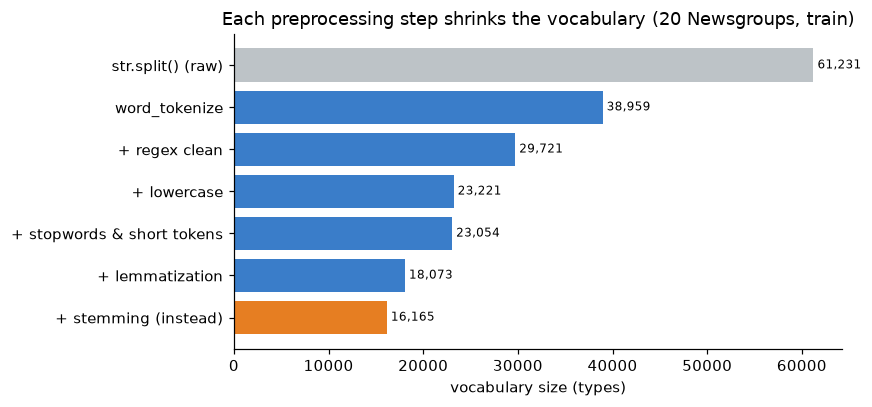

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#bdc3c7"] + ["#3a7dc9"] * 5 + ["#e67e22"]
ax.barh(steps.index[::-1], steps["vocabulary"][::-1], color=colors[::-1])
for i, v in enumerate(steps["vocabulary"][::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("vocabulary size (types)")
ax.set_title("Each preprocessing step shrinks the vocabulary (20 Newsgroups, train)")
plt.tight_layout(); plt.savefig(DOCS / "02_vocabulary_reduction.png", bbox_inches="tight"); plt.show()

Two things stand out. Removing stopwords barely changes the *vocabulary* (there are only ~200
stopwords) but nearly **halves the number of tokens** — those few words are that frequent (Zipf again).
Lemmatization and stemming, on the other hand, merge thousands of word forms.

A smaller vocabulary means fewer features, less sparsity and more reliable counts for each feature.
Stemming shrinks the vocabulary most, but at the cost of readability and of some wrong merges.

In [23]:
clean_counts = Counter(tok for text in train["text"] for tok in preprocess(text))
pd.DataFrame(clean_counts.most_common(25), columns=["token", "count"]).T

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
token,would,get,one,space,use,think,go,year,make,know,...,also,program,work,see,system,look,well,file,new,good
count,1303,1198,1068,1066,1040,1006,982,970,927,908,...,742,724,676,601,597,583,570,557,535,535


### There is no single "correct" pipeline
| Task | Typical choice |
|---|---|
| Topic classification, search | lowercase, remove stopwords, lemma or stem |
| Sentiment analysis | keep negations; maybe keep `!` and emoticons |
| Spam detection | numbers, URLs and CAPITALS can be strong signals — replace them with a placeholder instead of deleting |
| Authorship analysis | stopwords are the *signal* — keep them |

The rule: **preprocessing is part of the model.** Choose it for your task and validate it.

## 8 · Exercises

**Exercise 1.** Sentiment-friendly stopwords: build a stopword set that keeps `not`, `no`, `nor` and
every word ending in `n't`, and apply `preprocess` with it to *"The rocket was not bad, but I didn't
enjoy the launch."*

In [24]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Note that `clean_text` turns `didn't` into `didn t`, so the `t` is then dropped as a short token. To keep `n't` you would tokenize *before* removing the apostrophe — try it!

```python
keep = {w for w in STOP if w in {"not", "no", "nor"} or w.endswith("n't")}
s = "The rocket was not bad, but I didn't enjoy the launch."
print("default:      ", preprocess(s))
print("keep negation:", preprocess(s, keep=keep))
```
</details>

In [25]:
keep = {w for w in STOP if w in {"not", "no", "nor"} or w.endswith("n't")}
s = "The rocket was not bad, but I didn't enjoy the launch."
print("default:      ", preprocess(s))
print("keep negation:", preprocess(s, keep=keep))

default:       ['rocket', 'bad', 'enjoy', 'launch']
keep negation: ['rocket', 'not', 'bad', 'enjoy', 'launch']


**Exercise 2.** Compare the Porter and Snowball stemmers: how many distinct stems does each produce
on the `sci.space` training documents (use `preprocess(..., normalize=None)` first)? Show five words
they stem differently.

In [26]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
space_tokens = {tok for text in train.loc[train["category"] == "sci.space", "text"]
                for tok in preprocess(text, normalize=None)}
print("types before stemming:", len(space_tokens))
print("Porter stems:  ", len({porter.stem(w) for w in space_tokens}))
print("Snowball stems:", len({snowball.stem(w) for w in space_tokens}))
diff = sorted(w for w in space_tokens if porter.stem(w) != snowball.stem(w))[:5]
print({w: (porter.stem(w), snowball.stem(w)) for w in diff})
```
</details>

In [27]:
space_tokens = {tok for text in train.loc[train["category"] == "sci.space", "text"]
                for tok in preprocess(text, normalize=None)}
print("types before stemming:", len(space_tokens))
print("Porter stems:  ", len({porter.stem(w) for w in space_tokens}))
print("Snowball stems:", len({snowball.stem(w) for w in space_tokens}))
diff = sorted(w for w in space_tokens if porter.stem(w) != snowball.stem(w))[:5]
print({w: (porter.stem(w), snowball.stem(w)) for w in diff})

types before stemming: 11737
Porter stems:   8374
Snowball stems: 8328
{'abruptly': ('abruptli', 'abrupt'), 'alveolus': ('alveolu', 'alveolus'), 'annulus': ('annulu', 'annulus'), 'aptly': ('aptli', 'apt'), 'arsene': ('arsen', 'arsene')}


**Exercise 3.** For spam detection, numbers are informative. Write `clean_text_spam(text)` that
replaces numbers with the placeholder word `NUM` and URLs with `URL` (instead of deleting them), then
test it on an SMS spam message.

In [28]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
def clean_text_spam(text):
    text = URL_RE.sub(" URL ", text)
    text = NUMBER_RE.sub(" NUM ", text)
    text = NON_LETTER_RE.sub(" ", text)
    return SPACES_RE.sub(" ", text).strip()

sms = nlp_course.load_sms()
msg = sms.loc[sms["label"] == "spam", "text"].iloc[0]
print("RAW:  ", msg)
print("CLEAN:", clean_text_spam(msg))
```
</details>

In [29]:
def clean_text_spam(text):
    text = URL_RE.sub(" URL ", text)
    text = NUMBER_RE.sub(" NUM ", text)
    text = NON_LETTER_RE.sub(" ", text)
    return SPACES_RE.sub(" ", text).strip()

sms = nlp_course.load_sms()
msg = sms.loc[sms["label"] == "spam", "text"].iloc[0]
print("RAW:  ", msg)
print("CLEAN:", clean_text_spam(msg))

RAW:   Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
CLEAN: Free entry in NUM a wkly comp to win FA Cup final tkts NUM st May NUM Text FA to NUM to receive entry question std txt rate T C s apply NUM over NUM s


## Summary
- **Tokenization** is the first decision; NLTK's `word_tokenize` and `sent_tokenize` handle English
  contractions and abbreviations far better than `split()` or a naive regex.
- **Lowercasing** and **stopword removal** shrink the vocabulary and expose topic words — but can remove
  signal (negations, capitals) for some tasks.
- **Stemming** is fast and crude; **lemmatization** gives real words but needs a dictionary and the part
  of speech.
- **Regular expressions** clean URLs, e-mails, numbers and punctuation.
- Our `preprocess()` function (also `nlp_course.preprocess`) shrank the training vocabulary from
  61,231 raw `split()` types to 18,073 lemmas (30%), and halved the number of tokens.

**Next:** [03 · One-hot and Bag-of-Words](03_one_hot_and_bag_of_words.ipynb) — turning these tokens into vectors.